# Matplotlib

In [1]:
import matplotlib.pyplot as plt
import numpy as np

Самый базовый и простой график:

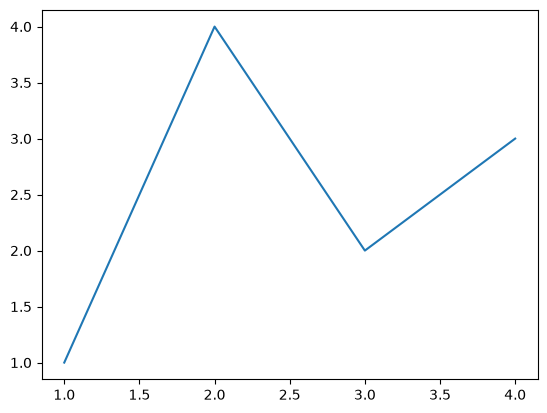

In [9]:
fig, ax = plt.subplots()             # Создать фигуру, содержащую одну область Axes.
ax.plot([1, 2, 3, 4], [1, 4, 2, 3])  # Построить некоторые данные на этой области Axes.
plt.show()                           # Показать фигуру.

## Части фигуры 

![Картинка](Parts_of_figure.PNG)

In [6]:
fig = plt.figure()             # пустая фигура без осей

<Figure size 640x480 with 0 Axes>

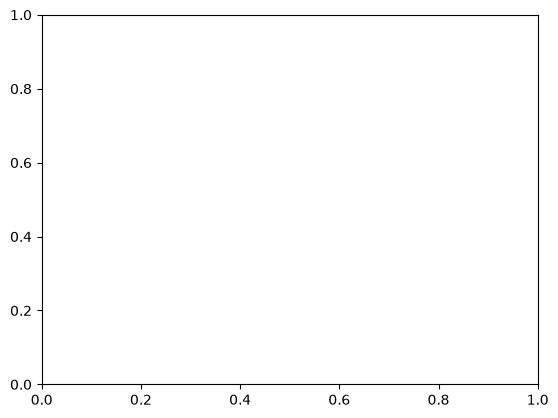

In [4]:
fig, ax = plt.subplots()       # фигура с одной осью

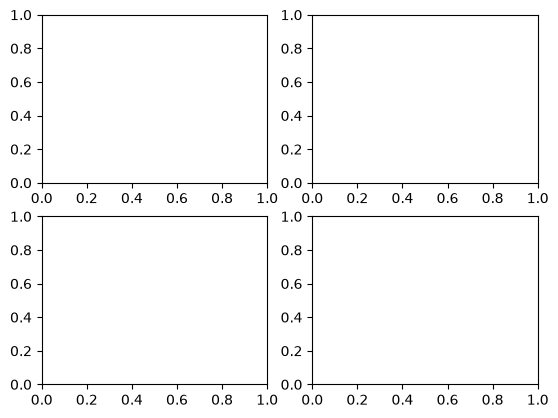

In [58]:
fig, axs = plt.subplots(2, 2)  # фигура с сеткой осей 2x2

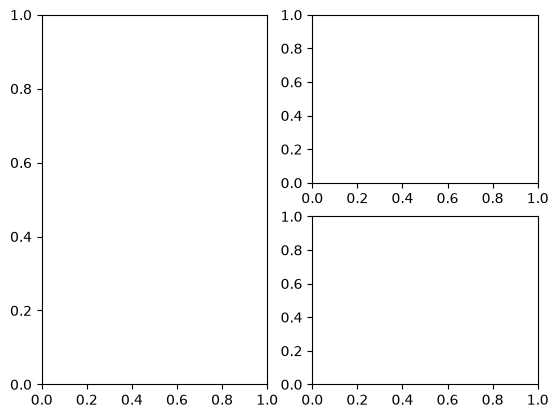

In [8]:
# фигура с одной осью слева и двумя справа:
fig, axs = plt.subplot_mosaic([['left', 'right_top'],
                               ['left', 'right_bottom']])

### Типы входных данных для функций построения графиков 

Руководство рекомендует матрицу превращать в ndarray:

In [11]:
b = np.matrix([[1, 2], [3, 4]])
print(type(b))
b_asarray = np.asarray(b)
print(type(b_asarray))

<class 'numpy.matrix'>
<class 'numpy.ndarray'>


График на основе словаря:

Text(0, 0.5, 'entry b')

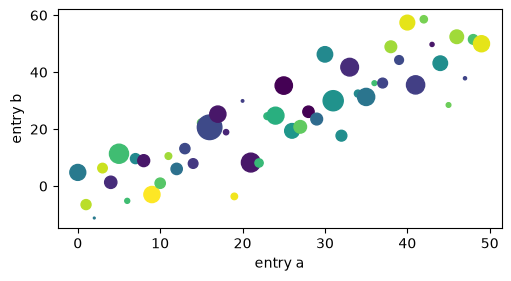

In [15]:
np.random.seed(19680801)  # seed the random number generator.
data = {'a': np.arange(50),
        'c': np.random.randint(0, 50, 50),
        'd': np.random.randn(50)}
data['b'] = data['a'] + 10 * np.random.randn(50)
data['d'] = np.abs(data['d']) * 100

fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')   # layout='constrained' — автоматически подгоняет отступы, чтобы подписи не наезжали друг на друга
ax.scatter('a', 'b', c='c', s='d', data=data)
ax.set_xlabel('entry a')
ax.set_ylabel('entry b')

## Стили кодирования (явные и неявные интерфейсы)

Объектно-ориентированный стиль:

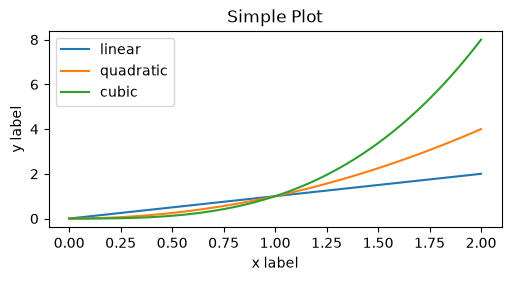

In [17]:
x = np.linspace(0, 2, 100)  # Пример данных.

# Заметь: даже в объектно-ориентированном стиле мы используем `.pyplot.figure` для создания фигуры.
fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')
ax.plot(x, x, label='linear')  # Рисуем данные на осях.
ax.plot(x, x**2, label='quadratic')  # Рисуем ещё данные на осях...
ax.plot(x, x**3, label='cubic')  # ... и ещё немного.
ax.set_xlabel('x label')  # Добавляем подпись оси X.
ax.set_ylabel('y label')  # Добавляем подпись оси Y.
ax.set_title("Simple Plot")  # Добавляем заголовок к осям.
ax.legend()  # Добавляем легенду.

В стиле pyplot:

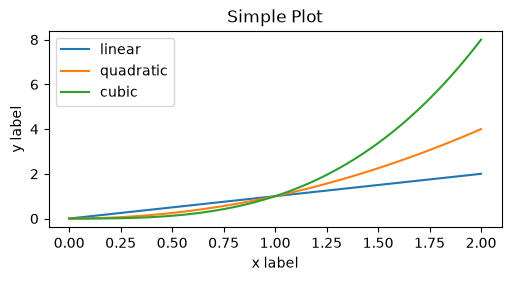

In [18]:
x = np.linspace(0, 2, 100)  # Sample data.

plt.figure(figsize=(5, 2.7), layout='constrained')
plt.plot(x, x, label='linear')  # Plot some data on the (implicit) Axes.
plt.plot(x, x**2, label='quadratic')  # etc.
plt.plot(x, x**3, label='cubic')
plt.xlabel('x label')
plt.ylabel('y label')
plt.title("Simple Plot")
plt.legend()

### Создание вспомогательных функций

In [19]:
def my_plotter(ax, data1, data2, param_dict):
    """
    Вспомогательная функция для построения графика.
    """
    out = ax.plot(data1, data2, **param_dict)
    return out

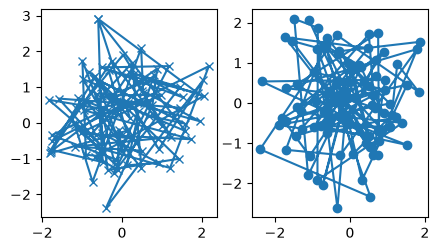

In [22]:
data1, data2, data3, data4 = np.random.randn(4, 100)  # make 4 random data sets
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(5, 2.7))
my_plotter(ax1, data1, data2, {'marker': 'x'})
my_plotter(ax2, data3, data4, {'marker': 'o'})

### Стилист-оформитель

Суть в том, что можно менять стиль уже после создания рисунка на оси, в данном случаи конкретно `linestyle`:

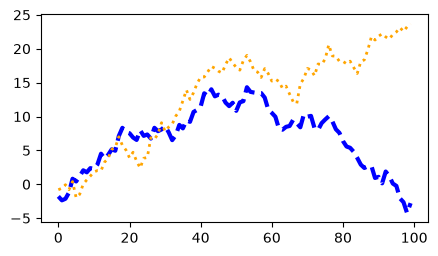

In [23]:
fig, ax = plt.subplots(figsize=(5, 2.7))
x = np.arange(len(data1))
ax.plot(x, np.cumsum(data1), color='blue', linewidth=3, linestyle='--')
l, = ax.plot(x, np.cumsum(data2), color='orange', linewidth=2)
l.set_linestyle(':')

### Цвета

- s - размер точки (площадь в пунктах²)
- facecolor - внутренняя заливка маркера
- edgecolor - граница (обводка) маркера

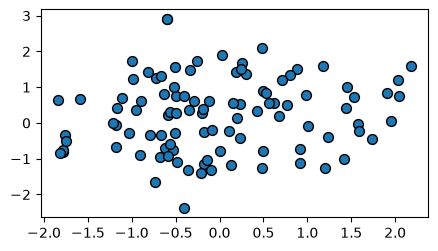

In [ ]:
fig, ax = plt.subplots(figsize=(5, 2.7))
_ = ax.scatter(data1, data2, s=50, facecolor='C0', edgecolor='k')

### Толщина линий, стили линий и размеры маркеров

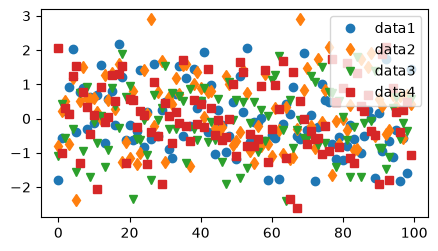

In [29]:
fig, ax = plt.subplots(figsize=(5, 2.7))
ax.plot(data1, 'o', label='data1')
ax.plot(data2, 'd', label='data2')
ax.plot(data3, 'v', label='data3')
ax.plot(data4, 's', label='data4')
ax.legend()

## Маркировка графиков

### Метки осей и текст

- density=True - Нормировать так, чтобы площадь под гистограммой была равна 1 (получается плотность вероятности, а не количество)
- alpha - прозрачность

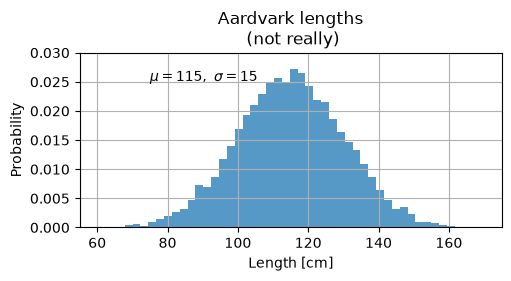

In [48]:
mu, sigma = 115, 15
x = mu + sigma * np.random.randn(10000)
fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')
# the histogram of the data
n, bins, patches = ax.hist(x, 50, density=True, facecolor='C0', alpha=0.75)

ax.set_xlabel('Length [cm]')
ax.set_ylabel('Probability')
ax.set_title('Aardvark lengths\n (not really)')
ax.text(75, .025, r'$\mu=115,\ \sigma=15$')   # Текст который ставится по координатам (координатом текущей осей!!!)
ax.axis([55, 175, 0, 0.03])   # X в диапазоне 55...175, а Y — в диапазоне 0...0.03
ax.grid(True)   # сетка

*r перед строкой — это raw string (сырая строка). В ней обратный слэш \ не является специальным символом и не интерпретируется как escape-последовательность.*

Мы так же можем использовать необязательные параметры которые не входят в дефолт функции. В данном примере мы можем указать не только название оси, но и размер с цветом при желании:

In [ ]:
t = ax.set_xlabel('my data', fontsize=14, color='red')

### Использование математических выражений в тексте

Ставя перед строкой `r` мы можем писать дефолтный формулы в формате TeX:

In [ ]:
ax.set_title(r'$\sigma_i=15$')

### Аннотации

- 1 параметр - название
- xy - куда указываем — точка на графике
- xytext - где стоит текст — точка с надписью (напоминаю, что координаты относительно осей графика, а не пиксели или что-то ещё)
- arrowprops=dict(...) - настройка текста:
    * facecolor - цвет заливки
    * shrink - отступ острия и хвоста от точек (в долях от длины)
    * и т.д.

(-2.0, 2.0)

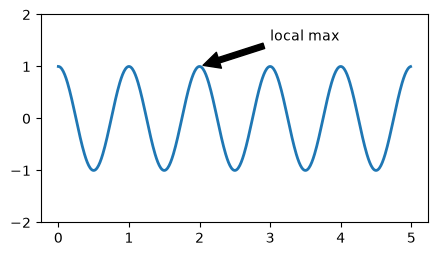

In [54]:
fig, ax = plt.subplots(figsize=(5, 2.7))

t = np.arange(0.0, 5.0, 0.01)
s = np.cos(2 * np.pi * t)
line, = ax.plot(t, s, lw=2)

ax.annotate('local max', xy=(2, 1), xytext=(3, 1.5),
            arrowprops=dict(facecolor='black', shrink=0.05))

ax.set_ylim(-2, 2)

### Легенды

Просто каждому графику даём название через `label` - это всё что нужно для отображение легенды:

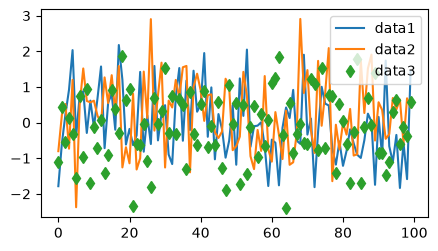

In [55]:
fig, ax = plt.subplots(figsize=(5, 2.7))
ax.plot(np.arange(len(data1)), data1, label='data1')
ax.plot(np.arange(len(data2)), data2, label='data2')
ax.plot(np.arange(len(data3)), data3, 'd', label='data3')
ax.legend()

## Шкалы и деления осей

### Весы

С помощью `set_yscale('log')` мы говорим оси в каком маштабе должна быть ось:

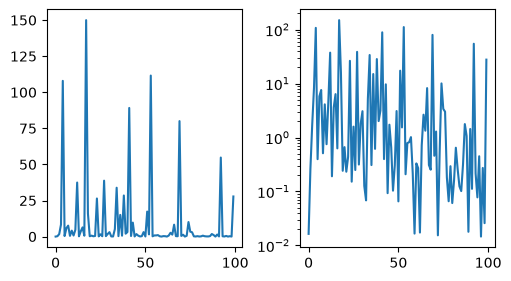

In [56]:
fig, axs = plt.subplots(1, 2, figsize=(5, 2.7), layout='constrained')
xdata = np.arange(len(data1))  # make an ordinal for this
data = 10**data1
axs[0].plot(xdata, data)

axs[1].set_yscale('log')
axs[1].plot(xdata, data)

### Указатели и форматировщики делений

Можем сами указать какие значения должны быть по осям и даже кастомно их подписать:

Text(0.5, 1.0, 'Manual ticks')

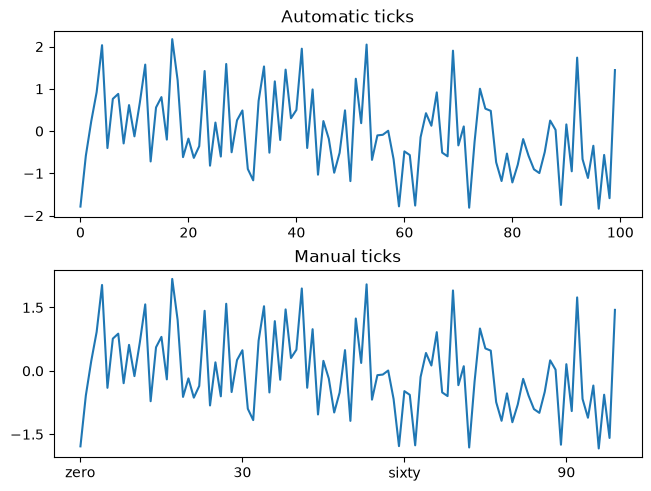

In [59]:
fig, axs = plt.subplots(2, 1, layout='constrained')
axs[0].plot(xdata, data1)
axs[0].set_title('Automatic ticks')

axs[1].plot(xdata, data1)
axs[1].set_xticks(np.arange(0, 100, 30), ['zero', '30', 'sixty', '90'])
axs[1].set_yticks([-1.5, 0, 1.5])  # note that we don't need to specify labels
axs[1].set_title('Manual ticks')

### Построение графиков дат и строк

- ax.xaxis.get_major_locator() - Возвращает локатор — объект, который определяет, где ставить основные деления на оси X
- ConciseDateFormatter(...) - Создаёт форматтер — объект, который решает, как подписывать каждое деление
- ax.xaxis.set_major_formatter(...) - Устанавливает этот форматтер для основных (major) делений оси X

*Очень поверхностно написал, при надобности смотреть конкретней*

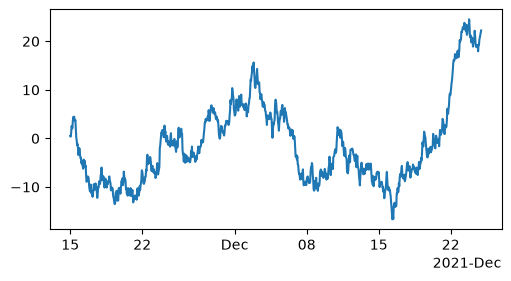

In [65]:
from matplotlib.dates import ConciseDateFormatter

np.random.seed(42)
fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')
dates = np.arange(np.datetime64('2021-11-15'), np.datetime64('2021-12-25'),
                  np.timedelta64(1, 'h'))
data = np.cumsum(np.random.randn(len(dates)))
ax.plot(dates, data)
ax.xaxis.set_major_formatter(ConciseDateFormatter(ax.xaxis.get_major_locator()))

Как это будет выглядеть без `ConciseDateFormatter`:

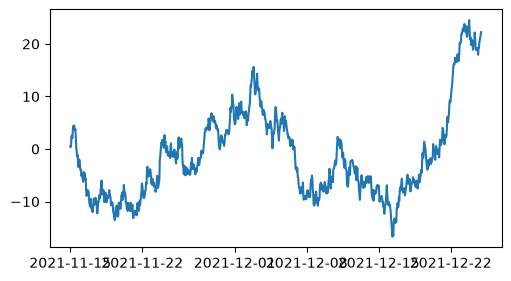

In [66]:
np.random.seed(42)
fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')
dates = np.arange(np.datetime64('2021-11-15'), np.datetime64('2021-12-25'),
                  np.timedelta64(1, 'h'))
data = np.cumsum(np.random.randn(len(dates)))
ax.plot(dates, data)

<BarContainer object of 4 artists>

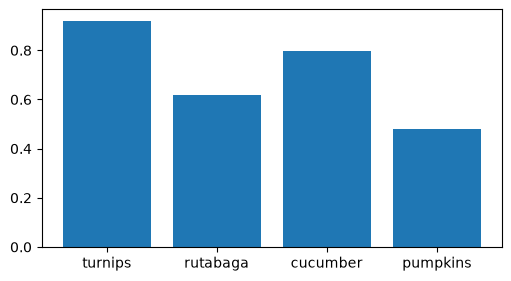

In [68]:
fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')
categories = ['turnips', 'rutabaga', 'cucumber', 'pumpkins']

ax.bar(categories, np.random.rand(len(categories)))

### Дополнительные объекты оси

Сложная тема, но по сути мы тут соединям несколько разных осей вместе:

Text(0.5, 0, 'Angle [°]')

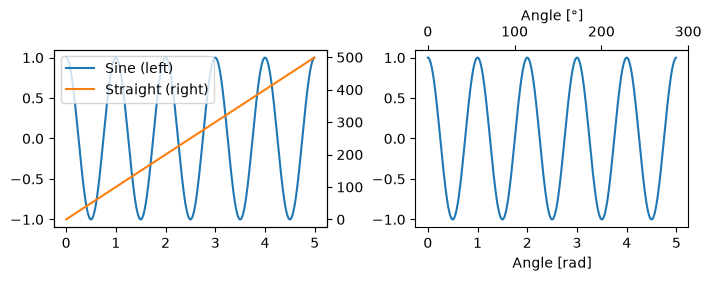

In [82]:
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(7, 2.7), layout='constrained')
l1, = ax1.plot(t, s)   # plot возвращает список линий. Берём первую линию
ax2 = ax1.twinx()   # создаёт вторую ось Y, которая живёт справа от графика, но использует ту же самую ось X, что и первая
l2, = ax2.plot(t, range(len(t)), 'C1')   # оранжевая линия
ax2.legend([l1, l2], ['Sine (left)', 'Straight (right)'])
# то есть по итогу у нас два графика, один ориентируется на свой y_left, второй на свой y_right

ax3.plot(t, s)
ax3.set_xlabel('Angle [rad]')
ax4 = ax3.secondary_xaxis('top', (np.rad2deg, np.deg2rad))   # создание оси x сверху
ax4.set_xlabel('Angle [°]')

## Данные, отображенные цветом

*Не стал разбирать эту тему, но посути это создание красивых тепловых карт*

Text(0.5, 1.0, 'scatter()')

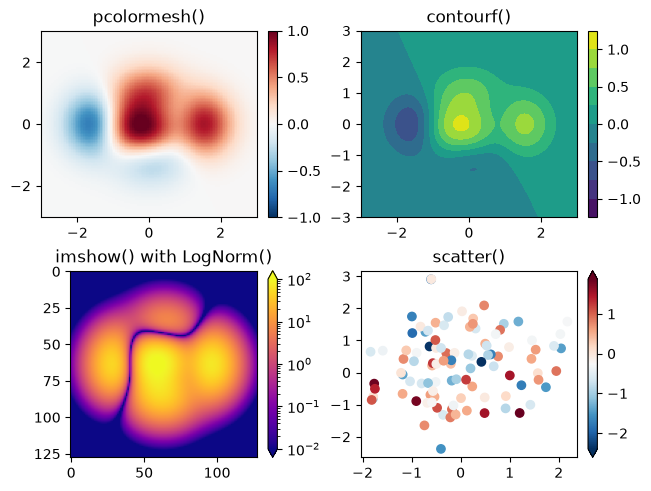

In [84]:
from matplotlib.colors import LogNorm

X, Y = np.meshgrid(np.linspace(-3, 3, 128), np.linspace(-3, 3, 128))
Z = (1 - X/2 + X**5 + Y**3) * np.exp(-X**2 - Y**2)

fig, axs = plt.subplots(2, 2, layout='constrained')

pc = axs[0, 0].pcolormesh(X, Y, Z, vmin=-1, vmax=1, cmap='RdBu_r')
fig.colorbar(pc, ax=axs[0, 0])
axs[0, 0].set_title('pcolormesh()')

co = axs[0, 1].contourf(X, Y, Z, levels=np.linspace(-1.25, 1.25, 11))
fig.colorbar(co, ax=axs[0, 1])
axs[0, 1].set_title('contourf()')

pc = axs[1, 0].imshow(Z**2 * 100, cmap='plasma', norm=LogNorm(vmin=0.01, vmax=100))
fig.colorbar(pc, ax=axs[1, 0], extend='both')
axs[1, 0].set_title('imshow() with LogNorm()')

pc = axs[1, 1].scatter(data1, data2, c=data3, cmap='RdBu_r')
fig.colorbar(pc, ax=axs[1, 1], extend='both')
axs[1, 1].set_title('scatter()')

## Работа с несколькими фигурами и осями

Уже проходили выше на самом деле:

Text(0.5, 1.0, 'right')

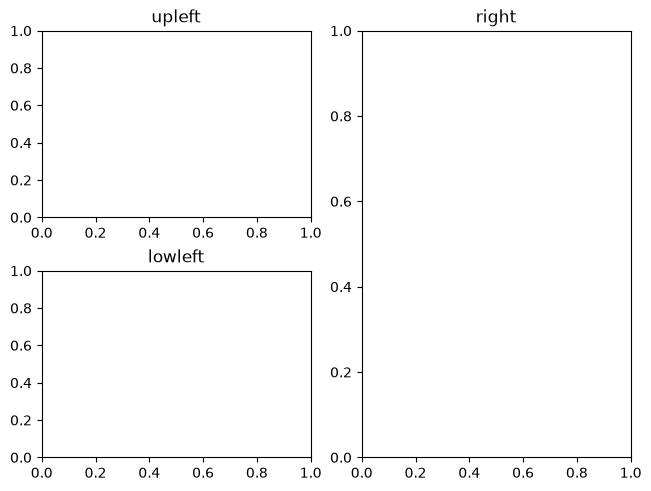

In [85]:
fig, axd = plt.subplot_mosaic([['upleft', 'right'],
                               ['lowleft', 'right']], layout='constrained')
axd['upleft'].set_title('upleft')
axd['lowleft'].set_title('lowleft')
axd['right'].set_title('right')